# Force-guided creep analysis: the original five-parameter GKV model

**Default data:** `User_Data/User400/Trial0` (23 October 2026).

The mechanical model is unchanged: a spring **E0** in series with two Kelvin–Voigt elements **(E1 || eta1)** and **(E2 || eta2)**. This notebook improves synchronization, force-based segmentation and the loading input; it does not add springs, dashpots or fitted drift terms.

Workflow: inspect raw measurements → align host timestamps → identify loading/holding/unloading/recovery from force → fit the same model to the measured force history → inspect loading and recovery residuals separately. The sequence log is a timing cross-check, not the segmentation source.

Run all cells with the **tonometry** Python environment. All thresholds and dimensions are collected below. Original CSV files are read-only; outputs go to `data_process/analysis_outputs/User400_Trial0`.


In [1]:
%matplotlib inline
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next(p for p in candidates if (p / 'User_Data').is_dir() and (p / 'data_process').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'data_process'))
from creep_force_preprocessing import load_trial, segment_cycles, flag_isolated_spikes
from creep_force_model import fit_gkv_history, simulate_gkv_history

TRIAL_DIR = REPO_ROOT / 'User_Data' / 'User400' / 'Trial0'
OUTPUT_DIR = REPO_ROOT / 'data_process' / 'analysis_outputs' / 'User400_Trial0'
SAVE_OUTPUTS = True
DT_S = 0.02                         # 50 Hz analysis grid; not a claim about hardware synchronization
BASELINE_S = 0.8
MAX_INTERPOLATION_GAP_S = 0.2
SEGMENTATION_SETTINGS = dict(min_force_n=.2, on_fraction=.2, off_fraction=.1, onset_fraction=.05,
                             debounce_s=.1, min_loaded_s=5., smoothing_s=.1,
                             plateau_guard_s=.8, stability_window_s=.5,
                             stable_std_fraction=.03, stable_slope_fraction=.05,
                             stable_confirm_s=.5, unload_guard_s=.25, recovery_guard_s=1.)
INDENTER_DIAMETER_MM = 12.45
RADIUS_MM = INDENTER_DIAMETER_MM / 2
SAMPLE_THICKNESS_MM = 12.0
SAMPLE_DIAMETER_MM = 64.0
POISSON_RATIO = None                # Unknown; do not silently substitute an incompressible value
TAU_BOUNDS_S = (0.5, 120.0)          # Report sensitivity/bound flags; sub-second transients are excluded
FIT_SCOPE = 'loading_and_recovery'  # Alternative: 'loading_only'
SAVE_FIGURES_DPI = 160
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'grid.alpha': 0.25})

def save_figure(fig, name):
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / f'{name}.png', dpi=SAVE_FIGURES_DPI, bbox_inches='tight')

print(f'Python: {sys.executable}')
print(f'Indenter radius: {RADIUS_MM:.3f} mm; a / thickness = {RADIUS_MM/SAMPLE_THICKNESS_MM:.3f}')


Python: /home/erielab/miniconda3/envs/tonometry/bin/python
Indenter radius: 6.225 mm; a / thickness = 0.519


## 1. Synchronization and signal conventions

Subtract the **same integer nanosecond origin before converting to seconds**. Sort/deduplicate timestamps explicitly and audit gaps and elapsed-time consistency. Do not independently reset each sensor's first sample or align force and displacement by cross-correlation: that could remove genuine viscoelastic lag.

The recorder saves **raw Fz**, even when GUI bias is enabled. Define compressive force as `-(Fz - initial_median_Fz)` using the first 0.8 s; stored bias is diagnostic metadata, not a second subtraction. Define indentation as `position - initial_median_position`, preserving the sign and recovery. Later cycles retain their residual deformation; do not zero every cycle for fitting.

Force and LVDT are aggregated into a shared 20 ms grid (force mean, displacement median). Only short interior gaps are interpolated; invalid/rail ADC samples and their repaired bins are excluded from fit residuals. Raw signals are retained for review. This improves time-axis consistency but cannot remove unknown sensor/USB latency: ATI timestamps are recorded after reading a stream buffer. The data therefore cannot establish a precise instantaneous modulus from the impact alone.


In [2]:
trial = load_trial(TRIAL_DIR, dt=DT_S, baseline_s=BASELINE_S, max_gap_s=MAX_INTERPOLATION_GAP_S)
force_raw, lvdt_raw, sequence = trial['force'], trial['lvdt'], trial['sequence']
sync = trial['sync'].copy()
audit = trial['audit']
display(audit if isinstance(audit, pd.DataFrame) else pd.json_normalize(audit))
display(pd.Series(trial['metadata'], name='Acquisition metadata').to_frame())
display(sync.head())


,source,samples,start_s,end_s,duration_s,mean_rate_hz,median_dt_s,p99_dt_s,max_gap_s,duplicate_timestamps,backward_timestamps,elapsed_clock_error_range_ms,rejected_samples
0,force,221915,0.000000,277.392011,277.392011,800.001411,0.000400,0.012806,0.105098,0,0,0.991129,0
1,lvdt,55882,0.001149,277.392784,277.391636,201.451640,0.002853,0.053989,0.157448,0,0,0.072573,4
2,sequence,42188,-0.000468,277.440844,277.441312,152.057383,0.005012,0.045416,0.130691,0,0,0.265607,0


,Acquisition metadata
origin_ns,1792774614986712767
dt_s,0.02
baseline_duration_s,0.8
force_baseline_raw_n,-0.892039
displacement_baseline_raw_mm,4.697878
compression_sign,-1.0
displacement_sign,1.0
force_bias_metadata_n,-0.849067
force_interpolated_bins,839
displacement_interpolated_bins,2488


,time_s,force_n,force_min_n,force_max_n,displacement_mm,force_observed,displacement_observed,repaired_displacement,valid,fit_valid
0,0.03,-0.010790,-0.099013,0.041577,-0.001354,True,True,False,True,True
1,0.05,-0.011137,-0.094343,0.085029,0.000666,True,True,False,True,True
2,0.07,-0.002840,-0.104857,0.079037,0.001332,True,True,False,True,True
3,0.09,-0.003651,-0.102702,0.082641,0.000000,True,True,False,True,True
4,0.11,0.011886,-0.047461,0.083662,0.001332,True,True,False,True,True


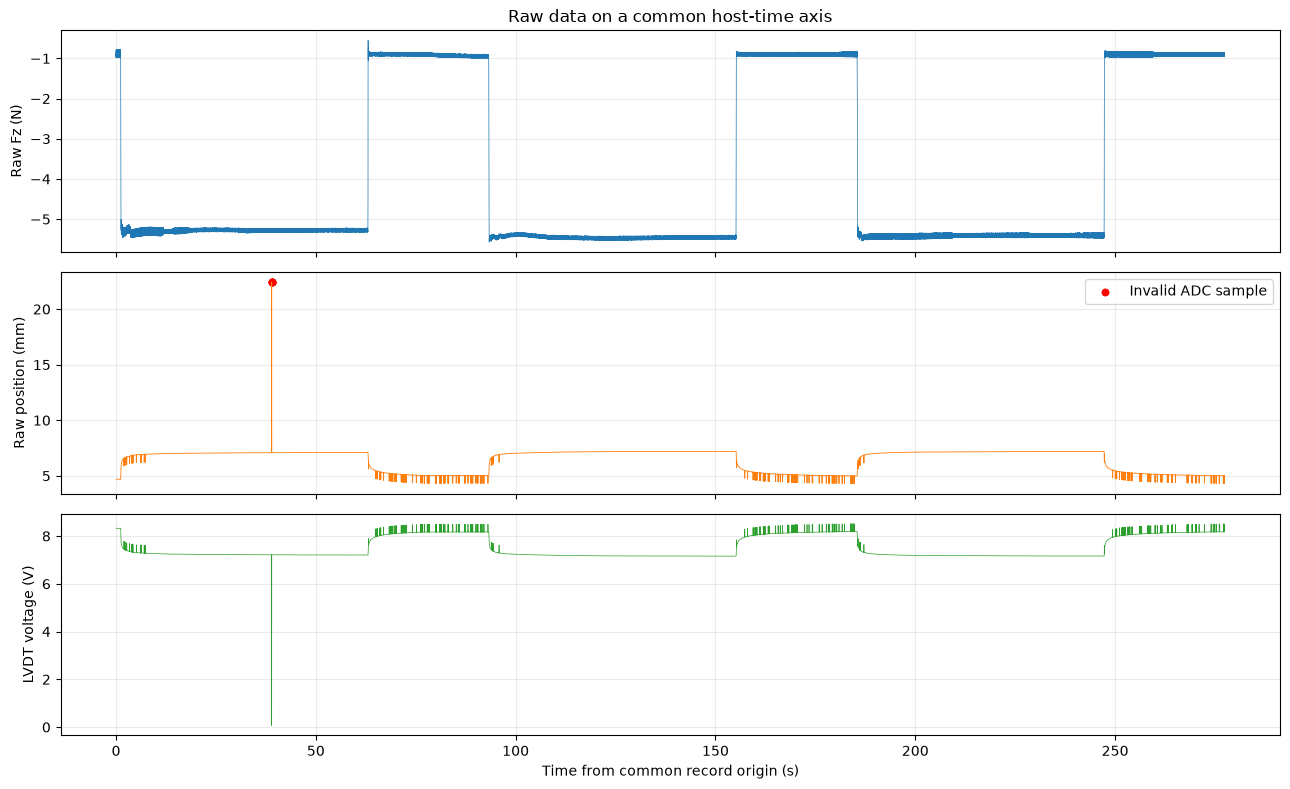

In [3]:
def plot_raw_data(trial):
    f, d = trial['force'], trial['lvdt']
    fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
    ax[0].plot(f['time_s'], f['Fz'], lw=0.5, color='tab:blue')
    ax[0].set_ylabel('Raw Fz (N)')
    ax[0].set_title('Raw data on a common host-time axis')
    ax[1].plot(d['time_s'], d['Position (mm)'], lw=0.6, color='tab:orange')
    ax[1].set_ylabel('Raw position (mm)')
    bad = ~d['sensor_valid'].to_numpy(bool)
    if bad.any():
        ax[1].scatter(d.loc[bad, 'time_s'], d.loc[bad, 'Position (mm)'], c='red', s=22, label='Invalid ADC sample')
        ax[1].legend()
    ax[2].plot(d['time_s'], d['Voltage (V)'], lw=0.5, color='tab:green')
    ax[2].set_ylabel('LVDT voltage (V)')
    ax[2].set_xlabel('Time from common record origin (s)')
    fig.tight_layout()
    return fig

fig = plot_raw_data(trial)
save_figure(fig, '01_raw_data')
plt.show()


## 2. Segment displacement using force events

Force hysteresis and a persistence check identify loaded intervals. Within each interval, force level, local variation and slope identify the first sustained stable loading segment. A guard before unloading excludes the transition. Low force after unloading identifies the recovery interval.

The phase labels are **baseline**, **loading/transient**, **stable_load**, **unloading**, and **recovery** (plus excluded gaps/guards). This is not a declaration that every force excursion is an electrical artifact: retain measured force peaks as input. Only the corresponding displacement observations can be excluded from a quasi-static fit.

Inspect the colored plot and cycle table before accepting automatic segmentation. Threshold-derived times are approximate host-time events, not exact mechanical contact times. No expected 60 s/30 s schedule is used to set them.

Within stable-load/recovery phases only, isolated displacement excursions above a 0.12 mm/local-MAD threshold and no longer than 0.06 s are marked as **suspected spikes**. Their original values remain in the synchronized export and gray plot; their residuals are excluded. This is a conservative quality-control flag, not proof of an electronic fault. Sustained changes and loading transitions are preserved.


In [4]:
cycles, phases = segment_cycles(sync, **SEGMENTATION_SETTINGS)
sync = sync.join(phases.drop(columns=['time_s', 'fit_valid']))
sync.loc[sync.time_s < BASELINE_S, 'phase'] = 'baseline'
sync['suspected_displacement_spike'] = flag_isolated_spikes(sync, phases)
sync['displacement_display_mm'] = sync.displacement_mm.where(~sync.suspected_displacement_spike)
if cycles.empty:
    raise RuntimeError('No valid load cycles were identified. Inspect raw force and segmentation thresholds.')
display(cycles)
print(sync.groupby('phase').size().rename('grid_samples'))
print('Suspected short displacement-spike bins (excluded, not deleted):', int(sync.suspected_displacement_spike.sum()))

timing_rows = []
if not sequence.empty:
    for c in cycles.itertuples():
        row = {'cycle': c.cycle, 'force_onset_s': c.onset_s, 'force_unload_start_s': c.unload_start_s}
        for action, event in (('bottom', c.onset_s), ('top', c.unload_start_s)):
            selected = sequence.sequence_status.astype(str).str.contains(f'Cycle {c.cycle}/', regex=False)
            selected &= sequence.sequence_status.astype(str).str.endswith(f'moving to {action}')
            command_time = sequence.loc[selected, 'time_s'].min()
            row[f'command_{action}_s'] = command_time
            row[f'force_event_minus_{action}_command_s'] = event-command_time
        timing_rows.append(row)
timing_crosscheck = pd.DataFrame(timing_rows)
display(timing_crosscheck)


,cycle,onset_s,ramp_end_s,stable_start_s,stable_end_s,unload_start_s,unload_end_s,recovery_start_s,recovery_end_s,ramp_duration_s,...,force_cv,raw_force_peak_n,force_drift_n_per_s,creep_gain_mm,preloading_baseline_mm,recovery_residual_mm,valid_fraction,observed_fraction,stable_fraction,flags
0,1,1.17,1.23,1.97,62.80,63.05,63.07,64.07,93.02,0.06,...,0.005111,4.576236,-0.000514,0.463284,-0.001354,0.333689,1.0,0.814276,0.995398,
1,2,93.27,93.35,94.07,154.92,155.17,155.21,156.21,185.20,0.08,...,0.005734,4.677532,0.000623,0.456226,0.334352,-0.037599,1.0,0.809232,0.996057,
2,3,185.45,185.55,186.27,247.02,247.27,247.31,248.31,277.37,0.10,...,0.004178,4.650491,-0.000561,0.430036,0.293401,0.022828,1.0,0.830317,0.996050,


phase
baseline               39
loading                12
pre_unload_guard       36
recovery             4352
recovery_settling     150
settling              109
stable_load          9123
unloaded               42
unloading               5
Name: grid_samples, dtype: int64
Suspected short displacement-spike bins (excluded, not deleted): 16


,cycle,force_onset_s,force_unload_start_s,command_bottom_s,force_event_minus_bottom_command_s,command_top_s,force_event_minus_top_command_s
0,1,1.17,63.05,1.005704,0.164296,62.763147,0.286853
1,2,93.27,155.17,93.162071,0.107929,154.980562,0.189438
2,3,185.45,247.27,185.282192,0.167808,247.087044,0.182956


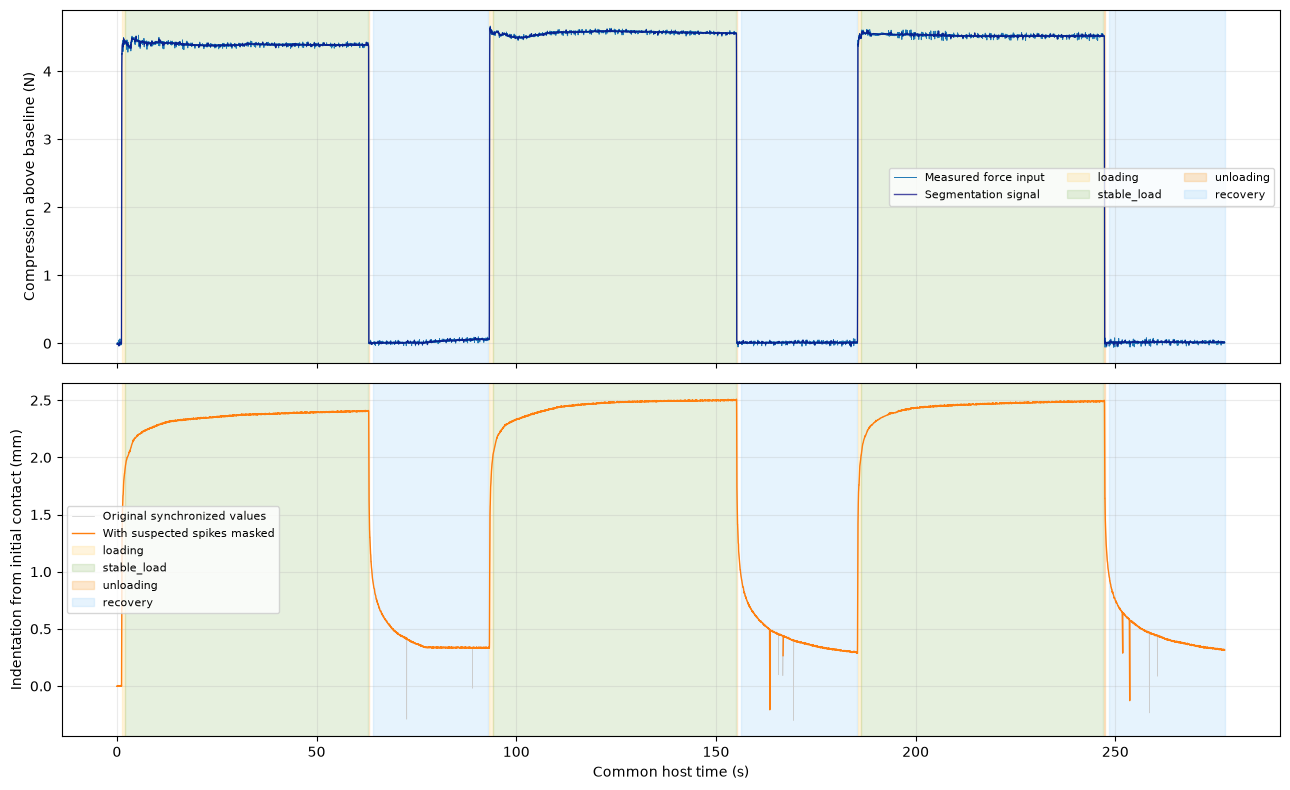

In [5]:
PHASE_COLORS = {'loading': '#ffd166', 'stable_load': '#90be6d', 'unloading': '#f8961e', 'recovery': '#90caf9'}

def shade_cycles(ax, cycles):
    first = True
    for c in cycles.itertuples():
        intervals = [('loading', c.onset_s, c.stable_start_s),
                     ('stable_load', c.stable_start_s, c.stable_end_s),
                     ('unloading', c.unload_start_s, c.unload_end_s),
                     ('recovery', c.recovery_start_s, c.recovery_end_s)]
        for name, start, stop in intervals:
            if np.isfinite(start) and np.isfinite(stop) and stop > start:
                ax.axvspan(start, stop, color=PHASE_COLORS[name], alpha=0.22, label=name if first else None)
        first = False

def plot_synchronized_data(sync, cycles):
    fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
    ax[0].plot(sync.time_s, sync.force_n, color='tab:blue', lw=0.7, label='Measured force input')
    ax[0].plot(sync.time_s, sync.force_segment_n, color='navy', lw=1, alpha=.7, label='Segmentation signal')
    ax[1].plot(sync.time_s, sync.displacement_mm, color='0.8', lw=.5, label='Original synchronized values')
    ax[1].plot(sync.time_s, sync.displacement_display_mm, color='tab:orange', lw=1, label='With suspected spikes masked')
    for a in ax:
        shade_cycles(a, cycles)
    ax[0].set_ylabel('Compression above baseline (N)')
    ax[1].set_ylabel('Indentation from initial contact (mm)')
    ax[1].set_xlabel('Common host time (s)')
    ax[0].legend(ncol=3, fontsize=8)
    ax[1].legend(fontsize=8)
    fig.tight_layout()
    return fig

fig = plot_synchronized_data(sync, cycles)
save_figure(fig, '02_synchronized_phases')
plt.show()


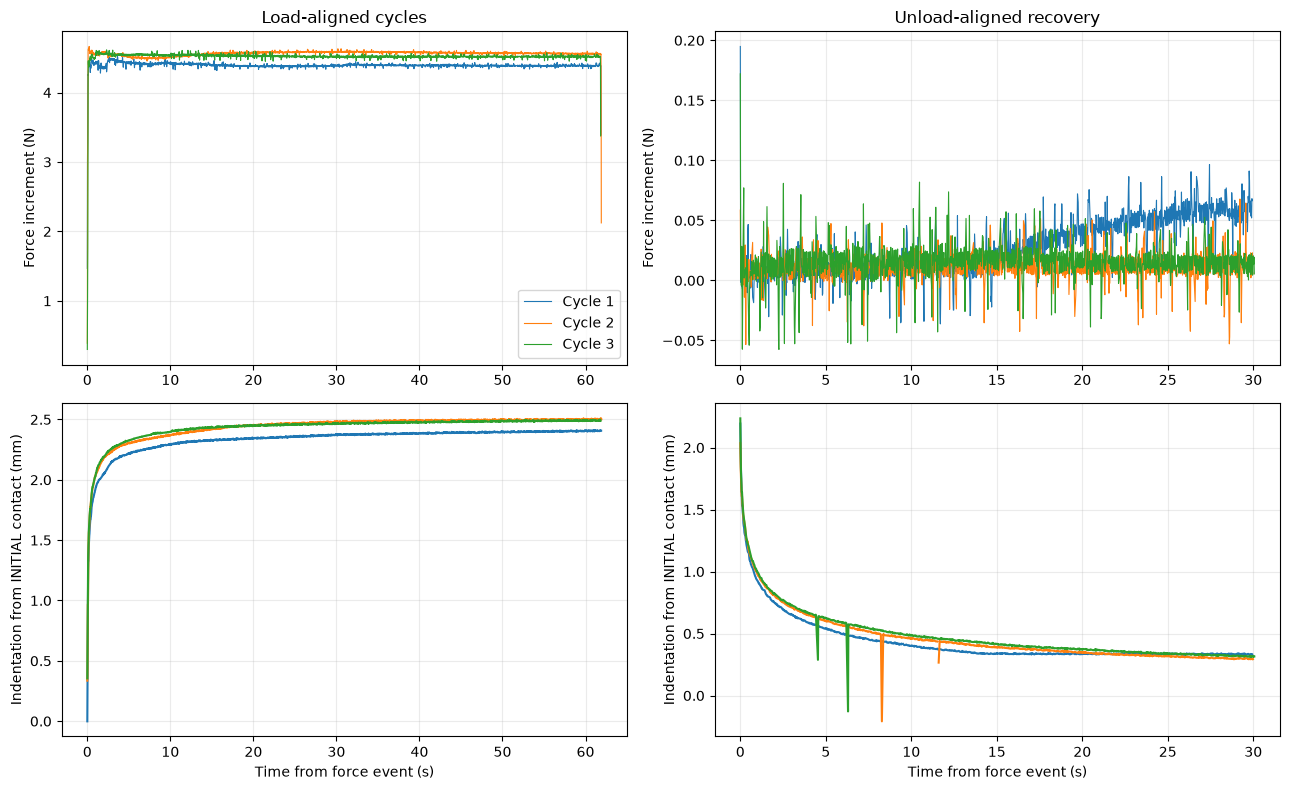

In [6]:
def plot_cycle_overlays(sync, cycles):
    fig, ax = plt.subplots(2, 2, figsize=(13, 8))
    for c in cycles.itertuples():
        load = sync.time_s.between(c.onset_s, c.unload_start_s)
        recovery = sync.time_s.between(c.unload_end_s, c.recovery_end_s)
        label = f'Cycle {c.cycle}'
        ax[0, 0].plot(sync.loc[load, 'time_s']-c.onset_s, sync.loc[load, 'force_n'], lw=.8, label=label)
        ax[1, 0].plot(sync.loc[load, 'time_s']-c.onset_s, sync.loc[load, 'displacement_display_mm'], label=label)
        ax[0, 1].plot(sync.loc[recovery, 'time_s']-c.unload_end_s, sync.loc[recovery, 'force_n'], lw=.8, label=label)
        ax[1, 1].plot(sync.loc[recovery, 'time_s']-c.unload_end_s, sync.loc[recovery, 'displacement_display_mm'], label=label)
    ax[0, 0].set_title('Load-aligned cycles')
    ax[0, 1].set_title('Unload-aligned recovery')
    for a in ax[0]:
        a.set_ylabel('Force increment (N)')
    for a in ax[1]:
        a.set_ylabel('Indentation from INITIAL contact (mm)')
        a.set_xlabel('Time from force event (s)')
    ax[0, 0].legend()
    fig.tight_layout()
    return fig

fig = plot_cycle_overlays(sync, cycles)
save_figure(fig, '03_cycle_overlays')
plt.show()


## 3. Same GKV model, measured force input

The original creep compliance is unchanged:

\[
J(t)=\frac{1}{E_0}+\frac{1}{E_1}(1-e^{-t/\tau_1})+\frac{1}{E_2}(1-e^{-t/\tau_2}),\qquad \tau_i=\eta_i/E_i.
\]

For a perfect step, the original expression is \(h(t)=P_0 J(t)/(2a)\). For the measured force profile, the same model gives

\[
h(t)=\frac{1}{2a}\int_{0^-}^{t}J(t-s)\,dF(s)
=\frac{1}{2a}\left[\frac{F(t)}{E_0}+\frac{q_1(t)}{E_1}+\frac{q_2(t)}{E_2}\right],\qquad
\tau_i\dot q_i+q_i=F(t),\quad q_i(0)=0.
\]

The implementation integrates a piecewise-linear force history exactly on each interval. It avoids differentiating noisy force. **All loading and unloading force samples remain in the history**, including excluded impact observations. Kelvin states continue across all three cycles. There are exactly five fitted parameters; no per-cycle offset or fitted drift is added.

Zero initial states assume the first contact baseline was initially relaxed. The 0.8 s baseline cannot establish this independently. Recovery fitting assumes the compensated indenter follows the sample without losing contact. Both assumptions must be checked experimentally.


In [7]:
def J_GKV(t, E0, E1, eta1, E2, eta2):
    t = np.asarray(t, dtype=float)
    return 1/E0 + (1-np.exp(-t/(eta1/E1)))/E1 + (1-np.exp(-t/(eta2/E2)))/E2

t = sync.time_s.to_numpy(float)
force = sync.force_n.to_numpy(float)
depth = sync.displacement_mm.to_numpy(float)
if not np.all(np.isfinite(force)):
    raise ValueError('Unfilled force gaps exist: inspect the audit; do not silently drop forcing history.')
valid = (sync['valid'].to_numpy(bool) & ~sync['repaired_displacement'].to_numpy(bool)
         & ~sync['suspected_displacement_spike'].to_numpy(bool))
loading_mask = valid & sync.phase.eq('stable_load').to_numpy()
recovery_mask = valid & sync.phase.eq('recovery').to_numpy()
baseline_mask = valid & sync.phase.eq('baseline').to_numpy()
fit_mask = loading_mask | baseline_mask
if FIT_SCOPE == 'loading_and_recovery':
    fit_mask |= recovery_mask
elif FIT_SCOPE != 'loading_only':
    raise ValueError('FIT_SCOPE must be loading_only or loading_and_recovery.')

fit = fit_gkv_history(t, force, depth, fit_mask, radius_mm=RADIUS_MM, tau_bounds=TAU_BOUNDS_S)
sync['fit_used'] = fit_mask
sync['predicted_mm'] = fit['prediction']
sync['residual_mm'] = depth - fit['prediction']
parameter_table = pd.DataFrame([
    {'parameter': key, 'value': value, 'unit': 'MPa s (apparent)' if key.startswith('eta') else 'MPa (apparent)'}
    for key, value in fit['parameters'].items()
])
display(parameter_table)
display(pd.DataFrame([{'tau1_s': fit['tau1'], 'tau2_s': fit['tau2'], 'RMSE_mm': fit['rmse'],
                      'R2': fit['r2'], 'scaled_Jacobian_condition': fit['jac_condition'],
                      'optimizer_success': fit['optimizer_success'], 'flags': '; '.join(fit['flags']) or 'none'}]))


,parameter,value,unit
0,E0,0.233124,MPa (apparent)
1,E1,0.769446,MPa (apparent)
2,eta1,1.671131,MPa s (apparent)
3,E2,0.566821,MPa (apparent)
4,eta2,23.705470,MPa s (apparent)


,tau1_s,tau2_s,RMSE_mm,R2,scaled_Jacobian_condition,optimizer_success,flags
0,2.171863,41.821798,0.070442,0.994297,53.258441,True,none


## 4. Validate phases and cycles, not only the full-curve R²

A high R² can be dominated by the large loading/unloading amplitude. Examine errors within each stable creep and recovery segment. A model that fits loading but misses recovery, or drifts systematically across cycles, has not established a common material response. It may reflect model inadequacy, preconditioning, contact changes, instrument compliance or baseline uncertainty.

The final cycle is also predicted using parameters fitted to the first two cycles only. The measured force of the final cycle is an allowed input; its displacement is not used for that fit. This is a repeatability check within one specimen, not independent biological/material validation.


In [8]:
def error_metrics(measured, predicted, mask):
    use = np.asarray(mask, bool) & np.isfinite(measured) & np.isfinite(predicted)
    if not use.any():
        return {'n': 0, 'RMSE_mm': np.nan, 'bias_mm': np.nan, 'R2': np.nan}
    y, yh = measured[use], predicted[use]
    sst = np.sum((y-y.mean())**2)
    return {'n': int(use.sum()), 'RMSE_mm': float(np.sqrt(np.mean((y-yh)**2))),
            'bias_mm': float(np.mean(y-yh)), 'R2': float(1-np.sum((y-yh)**2)/sst) if sst else np.nan}

rows = []
for c in cycles.itertuples():
    for phase in ('stable_load', 'recovery'):
        mask = valid & sync.cycle.eq(c.cycle).to_numpy() & sync.phase.eq(phase).to_numpy()
        rows.append({'cycle': c.cycle, 'phase': phase, **error_metrics(depth, fit['prediction'], mask)})
phase_metrics = pd.DataFrame(rows)
display(phase_metrics)
poor_phases = phase_metrics.loc[phase_metrics.R2 < 0, ['cycle', 'phase', 'R2']]
if not poor_phases.empty:
    display(Markdown('**Model check:** some within-phase R² values are negative despite a high whole-trial R². '
                     'The current common parameter set does not explain every creep/recovery segment; '
                     'report this discrepancy with the apparent parameters.'))
    display(poor_phases)

holdout_fit, holdout_metrics = None, pd.DataFrame()
if len(cycles) >= 3:
    heldout_cycle = int(cycles.cycle.iloc[-1])
    cutoff = float(cycles.onset_s.iloc[-1])
    train_mask = fit_mask & (t < cutoff)
    holdout_fit = fit_gkv_history(t, force, depth, train_mask, radius_mm=RADIUS_MM, tau_bounds=TAU_BOUNDS_S)
    holdout_metrics = pd.DataFrame([
        {'cycle': heldout_cycle, 'phase': phase, **error_metrics(depth, holdout_fit['prediction'],
          valid & sync.cycle.eq(heldout_cycle).to_numpy() & sync.phase.eq(phase).to_numpy())}
        for phase in ('stable_load', 'recovery')
    ])
    display(holdout_metrics)
    print('Holdout-fit flags:', ', '.join(holdout_fit['flags']) or 'none')


,cycle,phase,n,RMSE_mm,bias_mm,R2
0,1,stable_load,2487,0.116861,0.081648,-1.127838
1,1,recovery,1184,0.049302,0.036178,0.844280
2,2,stable_load,2473,0.053583,-0.025853,0.579425
3,2,recovery,1182,0.041175,0.019991,0.922688
4,3,stable_load,2526,0.048016,-0.024582,0.552766
5,3,recovery,1189,0.051673,0.038444,0.870232


**Model check:** some within-phase R² values are negative despite a high whole-trial R². The current common parameter set does not explain every creep/recovery segment; report this discrepancy with the apparent parameters.

,cycle,phase,R2
0,1,stable_load,-1.127838


,cycle,phase,n,RMSE_mm,bias_mm,R2
0,3,stable_load,2526,0.053997,-0.034257,0.434401
1,3,recovery,1189,0.063542,0.053529,0.803772


Holdout-fit flags: none


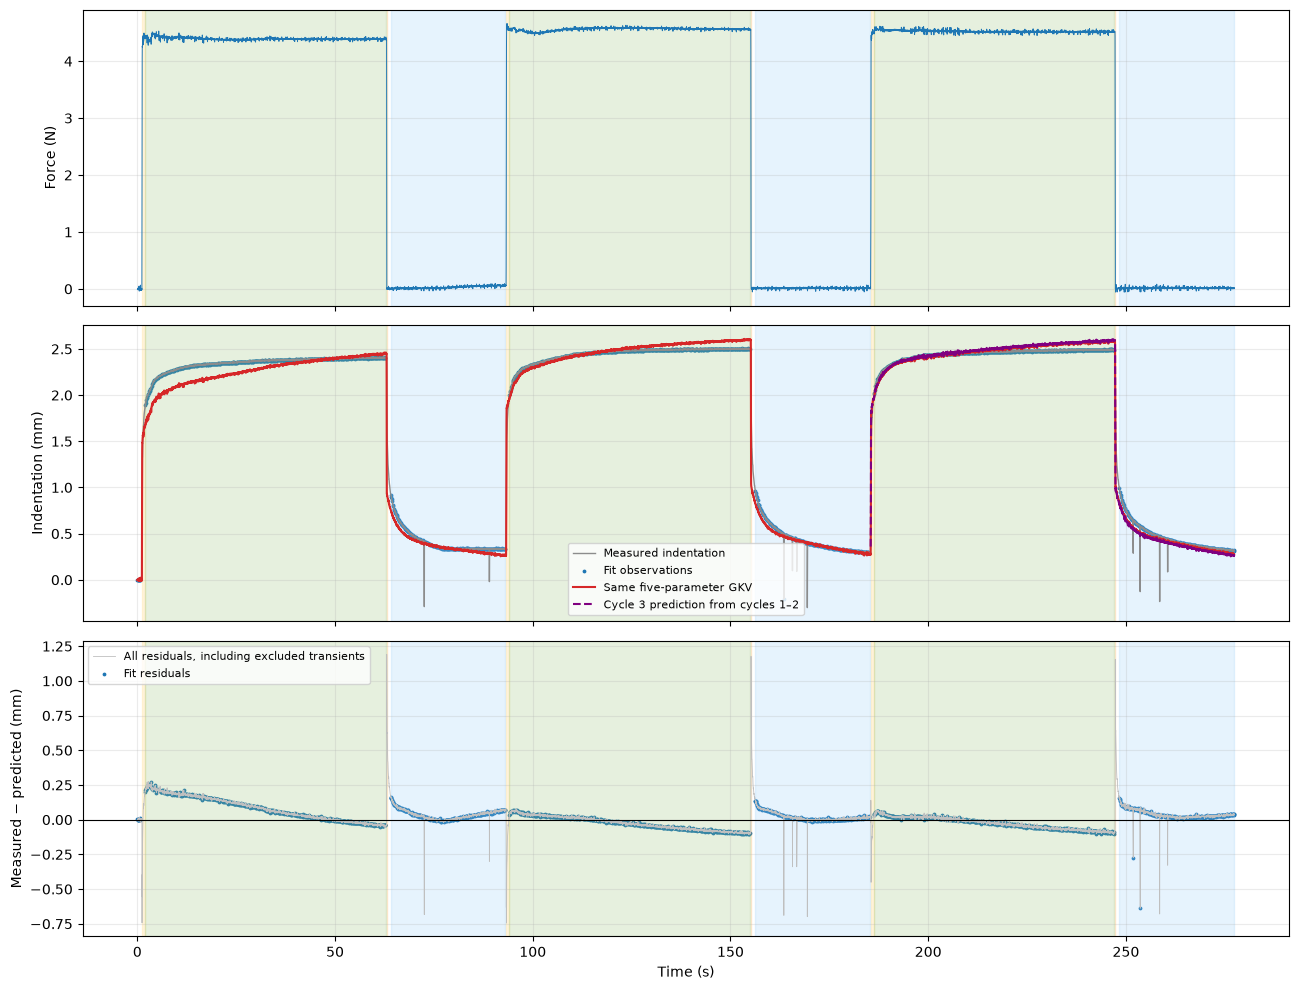

In [9]:
def plot_model_diagnostics(sync, cycles, fit, holdout_fit=None):
    fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
    ax[0].plot(sync.time_s, sync.force_n, lw=.7, label='Full measured force input')
    ax[0].set_ylabel('Force (N)')
    ax[1].plot(sync.time_s, sync.displacement_mm, color='0.55', lw=1, label='Measured indentation')
    used = sync.fit_used
    ax[1].scatter(sync.loc[used, 'time_s'][::5], sync.loc[used, 'displacement_mm'][::5], s=3, c='tab:blue', label='Fit observations')
    ax[1].plot(sync.time_s, fit['prediction'], color='tab:red', label='Same five-parameter GKV')
    if holdout_fit is not None:
        held = sync.time_s >= float(cycles.onset_s.iloc[-1])
        ax[1].plot(sync.loc[held, 'time_s'], holdout_fit['prediction'][held], '--', color='purple', label='Cycle 3 prediction from cycles 1–2')
    ax[1].set_ylabel('Indentation (mm)')
    ax[1].legend(fontsize=8)
    ax[2].plot(sync.time_s, sync.residual_mm, color='0.75', lw=.6, label='All residuals, including excluded transients')
    ax[2].scatter(sync.loc[used, 'time_s'][::3], sync.loc[used, 'residual_mm'][::3], c='tab:blue', s=3, label='Fit residuals')
    ax[2].axhline(0, c='black', lw=.8)
    ax[2].set_ylabel('Measured − predicted (mm)')
    ax[2].set_xlabel('Time (s)')
    ax[2].legend(fontsize=8)
    for a in ax:
        shade_cycles(a, cycles)
    fig.tight_layout()
    return fig

fig = plot_model_diagnostics(sync, cycles, fit, holdout_fit)
save_figure(fig, '04_gkv_fit_and_residuals')
plt.show()


## 5. Parameter interpretation and a focused sensitivity check

The original scaling \(h=FJ/(2a)\) is retained. For a rigid flat punch on a frictionless elastic half-space, it corresponds to a **reduced/apparent indentation modulus**, not directly Young's modulus. With constant known Poisson ratio, \(E=(1-\nu^2)E^*\). No Poisson ratio or finite-thickness correction is silently introduced here.

For this specimen, \(a/H\approx0.52\), and measured indentation is about 20% of the 12 mm thickness. Boundary support, finite thickness, finite strain and machine compliance can materially affect fitted moduli. Keep the same model, but label the five parameters **apparent** until those effects are independently calibrated. Sample diameter is 64 mm; dimensions alone do not specify whether its underside slips or is bonded.

Test modest changes to the transition exclusion. Time constants near the bounds, weakly separated branches, large parameter changes or systematic recovery residuals limit physical interpretation. Do not report optimizer covariance as experimental uncertainty: these samples are highly correlated and this is one trial.


In [10]:
# Same five parameters; only change which displacement observations enter the fit.
sensitivity_rows = []
for extra_guard_s in (0.0, 1.0):
    mask = fit_mask.copy()
    if extra_guard_s:
        for c in cycles.itertuples():
            mask &= ~((t >= c.stable_start_s) & (t < c.stable_start_s + extra_guard_s))
            mask &= ~((t >= c.recovery_start_s) & (t < c.recovery_start_s + extra_guard_s))
    result = fit if extra_guard_s == 0 else fit_gkv_history(
        t, force, depth, mask, radius_mm=RADIUS_MM, tau_bounds=TAU_BOUNDS_S, max_starts=3)
    sensitivity_rows.append({'extra_transition_exclusion_s': extra_guard_s,
                             **result['parameters'], 'tau1_s': result['tau1'], 'tau2_s': result['tau2'],
                             'RMSE_mm': result['rmse'], 'flags': '; '.join(result['flags']) or 'none'})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

geometry_summary = pd.DataFrame([{
    'indenter_diameter_mm': INDENTER_DIAMETER_MM, 'sample_thickness_mm': SAMPLE_THICKNESS_MM,
    'sample_diameter_mm': SAMPLE_DIAMETER_MM, 'radius_to_thickness': RADIUS_MM/SAMPLE_THICKNESS_MM,
    'observed_max_valid_depth_mm': float(np.nanmax(depth[valid])),
    'observed_depth_to_thickness': float(np.nanmax(depth[valid])/SAMPLE_THICKNESS_MM),
    'poisson_ratio': POISSON_RATIO, 'finite_thickness_correction_applied': False}])
display(geometry_summary)


,extra_transition_exclusion_s,E0,E1,eta1,E2,eta2,tau1_s,tau2_s,RMSE_mm,flags
0,0.0,0.233124,0.769446,1.671131,0.566821,23.705470,2.171863,41.821798,0.070442,none
1,1.0,0.227555,0.838541,1.838741,0.568626,23.737492,2.192785,41.745344,0.068327,none


,indenter_diameter_mm,sample_thickness_mm,sample_diameter_mm,radius_to_thickness,observed_max_valid_depth_mm,observed_depth_to_thickness,poisson_ratio,finite_thickness_correction_applied
0,12.45,12.0,64.0,0.51875,2.509057,0.209088,None,False


## 6. Export and decision guide

Use the force-defined stable loading segments for descriptive creep comparisons. Use the full measured force history to estimate the same GKV parameters. Accept a material interpretation only after inspecting phase residuals, the held-out cycle and parameter sensitivity. If recovery remains inconsistent, report the discrepancy rather than changing segmentation to make the curves fit.

For the next experiment, improve independent timing/latency calibration, verify unloaded contact, and collect longer recovery plus repeat trials. Multiple load levels help check linearity. These are checks on the existing model, not additional fitted mechanisms.


In [11]:
def serializable(value):
    if isinstance(value, dict):
        return {k: serializable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [serializable(v) for v in value]
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.bool_):
        return bool(value)
    return value

if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    cycles.to_csv(OUTPUT_DIR / 'force_defined_cycles.csv', index=False)
    audit.to_csv(OUTPUT_DIR / 'timestamp_audit.csv', index=False)
    timing_crosscheck.to_csv(OUTPUT_DIR / 'force_vs_sequence_timing.csv', index=False)
    sync.to_csv(OUTPUT_DIR / 'synchronized_segmented_data.csv', index=False)
    parameter_table.to_csv(OUTPUT_DIR / 'gkv_parameters.csv', index=False)
    phase_metrics.to_csv(OUTPUT_DIR / 'phase_fit_metrics.csv', index=False)
    holdout_metrics.to_csv(OUTPUT_DIR / 'heldout_cycle_metrics.csv', index=False)
    sensitivity.to_csv(OUTPUT_DIR / 'transition_sensitivity.csv', index=False)
    geometry_summary.to_csv(OUTPUT_DIR / 'geometry_and_assumptions.csv', index=False)
    summary = {k: fit[k] for k in ('parameters', 'tau1', 'tau2', 'rmse', 'r2', 'flags', 'jac_condition', 'optimizer_success')}
    summary.update({'model': 'E0 in series with (E1 || eta1) and (E2 || eta2)',
                    'fit_scope': FIT_SCOPE, 'dt_s': DT_S, 'radius_mm': RADIUS_MM,
                    'tau_bounds_s': TAU_BOUNDS_S, 'source_trial': str(TRIAL_DIR.relative_to(REPO_ROOT)),
                    'parameter_interpretation': 'Apparent indentation parameters under the original 1/(2a) scaling; no finite-thickness correction.'})
    summary['poor_phase_fits'] = poor_phases.to_dict(orient='records')
    summary['acquisition_metadata'] = trial['metadata']
    summary['suspected_displacement_spike_bins'] = int(sync.suspected_displacement_spike.sum())
    (OUTPUT_DIR / 'analysis_summary.json').write_text(json.dumps(serializable(summary), indent=2), encoding='utf-8')
    print(f'Exported analysis and four figures to: {OUTPUT_DIR}')


Exported analysis and four figures to: /home/erielab/Git_repo/Hoang_Tonometry_Control_Code/data_process/analysis_outputs/User400_Trial0


## References and implementation notes

- [Efremov et al., *Viscoelasticity in simple indentation-cycle experiments* (2020)](https://doi.org/10.1038/s41598-020-70361-y): indentation geometry and loading/unloading correspondence; constant-area cylindrical contact is a special case. Contact loss invalidates a simple continuous-contact interpretation.
- [COMSOL, Linear Viscoelasticity: generalized Kelvin–Voigt model](https://doc.comsol.com/6.3/doc/com.comsol.help.sme/sme_ug_theory.06.029.html): elastic compliance plus Kelvin elements and internal-state evolution.
- [LabJack eStreamRead documentation](https://support.labjack.com/docs/estreamread-ljm-user-s-guide): buffered scans and backlog explain why host read timestamps need not equal physical sample times.

Numerical helpers are in `creep_force_preprocessing.py` and `creep_force_model.py` beside this notebook. Synthetic regression tests check phase segmentation, timestamp precision, gap handling and equivalence to the original step-response model. The imported model keeps exactly five fitted parameters.
